# GPU-accelerated conformer workflows with nvMolKit

**Note:** This is a guest post from Kevin Boyd at NVIDIA.

[nvMolKit](https://github.com/NVIDIA-BioNeMo/nvMolKit) is an open-source library
with GPU-accelerated, batched implementations of common RDKit operations. Its APIs
closely follow RDKit's, so a loop of RDKit calls can usually be replaced with a
single batched nvMolKit call. Installation and API details are in the
[nvMolKit documentation](https://nvidia-bionemo.github.io/nvMolKit/).

We previously covered nvMolKit's fingerprinting, similarity, and clustering
functionality [here](https://greglandrum.github.io/rdkit-blog/posts/2026-02-28-nvmolkit-clustering.html).
In this post, we'll cover common RDKit 3D functionality that nvMolKit supports,
using a four-step conformer workflow:

1. **Conformer generation:** 50 ETKDGv3 conformers per molecule.
2. **Force field minimization:** MMFF94 minimization of every conformer.
3. **3D descriptors:** shape descriptors for every conformer.
4. **Conformer pruning:** all-pairs torsion fingerprint deviation (TFD) matrices,
   used to remove redundant conformers.

Each step is run with RDKit on the CPU and with nvMolKit on the GPU. We check that
the results agree, then compare timings.

## Installation

nvMolKit is available on conda-forge alongside RDKit and requires an NVIDIA GPU
with compute capability 7.0 (V100) or newer. Both packages can be installed into
the same environment:

```bash
conda install -c conda-forge rdkit nvmolkit jupyterlab
```

nvMolKit depends on PyTorch, which we also use here to confirm that CUDA is
available and to synchronize the GPU before reading timers. conda normally
installs a CUDA build of PyTorch; if `torch.cuda.is_available()` returns `False`
in the next cell, add `"pytorch=*=cuda*"` to the install command.

In [1]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from time import perf_counter
import gzip
import importlib.metadata
import multiprocessing
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, rdBase
from rdkit.Chem import AllChem, rdDistGeom, rdMolDescriptors, TorsionFingerprints
from rdkit.ML.Cluster import Butina

from nvmolkit.descriptors3d import Calc3DProperties, Property3D
from nvmolkit.embedMolecules import EmbedMolecules
from nvmolkit.mmffOptimization import MMFFOptimizeMoleculesConfs
from nvmolkit.tfd import GetTFDMatrices
from nvmolkit.types import FireOptions, HardwareOptions, PrecisionMode

print("Python:", platform.python_version())
print("RDKit:", rdBase.rdkitVersion)
print("nvMolKit:", importlib.metadata.version("nvmolkit"))
print("PyTorch:", torch.__version__)
assert torch.cuda.is_available(), "CUDA is required for nvMolKit"
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.14.10
RDKit: 2026.03.6
nvMolKit: 0.7.0
PyTorch: 2.14.1


GPU: NVIDIA GeForce RTX 5080


## Configuration

The timings below were collected on an NVIDIA GeForce RTX 5080 and an AMD Ryzen 9
9950X, with both RDKit and nvMolKit limited to 16 CPU threads. A random
1,000-molecule Enamine REAL sample is included with this post. Additional molecules
are available from the
[Enamine REAL 10.4M sample](https://enamine.net/compound-collections/real-compounds/real-database-subsets).

The choice of minimizer and iteration limits is discussed in step 2 and in the appendix.

In [2]:
# Number of molecules to process
n_mols = 1000

# Conformers to generate per molecule
n_confs = 50

# CPU threads for RDKit and for nvMolKit's CPU-side preprocessing
n_cpu_threads = 16

# Force-field iteration limits: RDKit (BFGS) and nvMolKit (FIRE)
max_mmff_iters = 200
fire_iters = 400

# ETKDG random seed
random_seed = 42

# Floating-point precision for the nvMolKit ETKDG and MMFF stages
gpu_precision = PrecisionMode.SINGLE

smi_file = Path("../data/enamine_real_1000.cxsmiles.gz")
assert smi_file.exists(), f"Enamine REAL file not found: {smi_file}"

hardware_options = HardwareOptions(preprocessingThreads=n_cpu_threads, gpuIds=[0])

### A note on precision

nvMolKit can run ETKDG and the force-field minimizers in either double
(`PrecisionMode.FULL`) or single (`PrecisionMode.SINGLE`) precision. Consumer
GPUs like the RTX 5080 have much higher single-precision than double-precision
throughput, and conformer generation and minimization don't need 15
significant digits. Here we use single precision for both stages. If you'd
rather match RDKit's arithmetic as closely as possible, set
`gpu_precision = PrecisionMode.FULL`; it's slower but still runs entirely on the
GPU.

## Loading molecules

The bundled sample contains 1,000 randomly selected molecules for which RDKit has
complete MMFF parameters. Parsing and hydrogen addition are not included in the
timings.

In [3]:
mols = []
with gzip.open(smi_file, "rt") as inf:
    next(inf)
    for line in inf:
        mol = Chem.MolFromSmiles(line.split("\t", 1)[0])
        if mol is None:
            continue
        mol = Chem.AddHs(mol)
        if not AllChem.MMFFHasAllMoleculeParams(mol):
            continue
        mols.append(mol)
        if len(mols) == n_mols:
            break

assert len(mols) == n_mols, f"Expected {n_mols:,} molecules, loaded {len(mols):,}"
print(f"Loaded {len(mols):,} molecules")
print(f"Median heavy atoms: {np.median([m.GetNumHeavyAtoms() for m in mols]):.0f}")

Loaded 1,000 molecules
Median heavy atoms: 26


## Step 1: ETKDG conformer generation

Both implementations generate 50 conformers per molecule with ETKDGv3,
random-coordinate initialization, and the same random seed. RDKit parallelizes
each molecule's conformers over 16 CPU threads; nvMolKit embeds the full batch of
molecules on the GPU.

Small untimed calls beforehand absorb one-time setup costs such as CUDA context
creation.

In [4]:
rd_params = rdDistGeom.ETKDGv3()
rd_params.useRandomCoords = True
rd_params.randomSeed = random_seed
rd_params.numThreads = n_cpu_threads

nv_params = rdDistGeom.ETKDGv3()
nv_params.useRandomCoords = True
nv_params.randomSeed = random_seed

rd_warmup = Chem.Mol(mols[0])
rdDistGeom.EmbedMultipleConfs(rd_warmup, numConfs=2, params=rd_params)
nv_warmup = [Chem.Mol(m) for m in mols[:4]]
EmbedMolecules(
    nv_warmup,
    nv_params,
    confsPerMolecule=2,
    hardwareOptions=hardware_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()

In [5]:
rdkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
for mol in rdkit_embedded:
    rdDistGeom.EmbedMultipleConfs(mol, numConfs=n_confs, params=rd_params)
rdkit_embed_time = perf_counter() - t0

rdkit_n_confs = sum(m.GetNumConformers() for m in rdkit_embedded)
print(f"RDKit ETKDG: {rdkit_embed_time:.2f} s ({rdkit_n_confs:,} conformers)")

RDKit ETKDG: 113.43 s (49,950 conformers)


In [6]:
nvmolkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
EmbedMolecules(
    nvmolkit_embedded,
    nv_params,
    confsPerMolecule=n_confs,
    hardwareOptions=hardware_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()
nvmolkit_embed_time = perf_counter() - t0

nvmolkit_n_confs = sum(m.GetNumConformers() for m in nvmolkit_embedded)
print(f"nvMolKit ETKDG: {nvmolkit_embed_time:.2f} s ({nvmolkit_n_confs:,} conformers)")

nvMolKit ETKDG: 19.82 s (49,950 conformers)


ETKDG occasionally fails to embed a molecule. To keep the comparisons below
one-to-one, molecules that either implementation failed to embed are dropped.

In [7]:
embedded_both = [
    i
    for i, (rd, nv) in enumerate(zip(rdkit_embedded, nvmolkit_embedded))
    if rd.GetNumConformers() and nv.GetNumConformers()
]
print(f"Dropping {len(mols) - len(embedded_both)} molecule(s) without conformers")
rdkit_embedded = [rdkit_embedded[i] for i in embedded_both]
nvmolkit_embedded = [nvmolkit_embedded[i] for i in embedded_both]

Dropping 1 molecule(s) without conformers


### Conformer ensemble comparison

ETKDG is stochastic, and the CPU and GPU implementations consume random numbers
differently, so conformers with the same ID in the two runs are not the same
structure. Instead, we compare the ensembles: every conformer from both
implementations is scored with RDKit MMFF94, and we plot each molecule's median
energy per atom. Ensembles of similar quality fall along the diagonal.

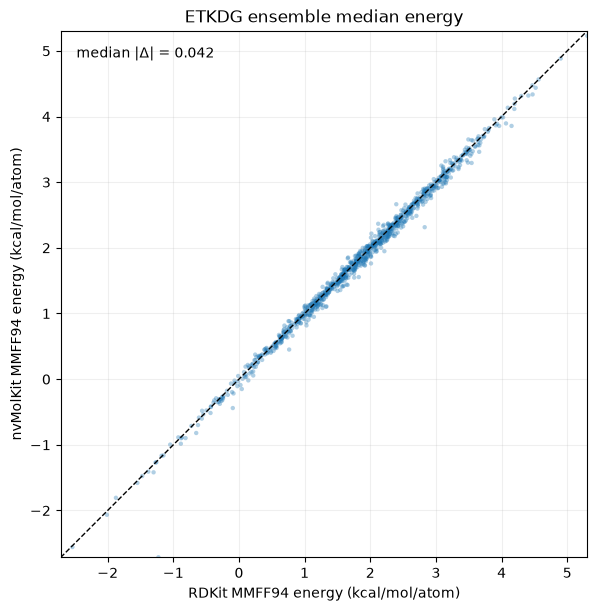

In [8]:
def mmff94_energies_per_atom(molecules):
    energy_groups = []
    for mol in molecules:
        props = AllChem.MMFFGetMoleculeProperties(mol, mmffVariant="MMFF94")
        energies = []
        for conf in mol.GetConformers():
            ff = AllChem.MMFFGetMoleculeForceField(
                mol,
                props,
                nonBondedThresh=100.0,
                confId=conf.GetId(),
                ignoreInterfragInteractions=True,
            )
            energies.append(ff.CalcEnergy() / mol.GetNumAtoms())
        energy_groups.append(np.asarray(energies))
    return energy_groups


def identity_panel(ax, x, y, title, annotation, *, s=10, alpha=0.35):
    finite = np.isfinite(x) & np.isfinite(y)
    x = np.asarray(x)[finite]
    y = np.asarray(y)[finite]
    lower = min(np.quantile(x, 0.001), np.quantile(y, 0.001))
    upper = max(np.quantile(x, 0.999), np.quantile(y, 0.999))
    ax.scatter(x, y, s=s, alpha=alpha, edgecolors="none")
    ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
    ax.set(xlim=(lower, upper), ylim=(lower, upper), title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, va="top")
    ax.grid(alpha=0.2)


rdkit_etkdg_energy_groups = mmff94_energies_per_atom(rdkit_embedded)
nvmolkit_etkdg_energy_groups = mmff94_energies_per_atom(nvmolkit_embedded)
rdkit_etkdg_medians = np.asarray([np.median(x) for x in rdkit_etkdg_energy_groups])
nvmolkit_etkdg_medians = np.asarray([np.median(x) for x in nvmolkit_etkdg_energy_groups])

fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
identity_panel(
    ax,
    rdkit_etkdg_medians,
    nvmolkit_etkdg_medians,
    "ETKDG ensemble median energy",
    f"median |Δ| = {np.median(np.abs(rdkit_etkdg_medians - nvmolkit_etkdg_medians)):.3g}",
)
ax.set_xlabel("RDKit MMFF94 energy (kcal/mol/atom)")
ax.set_ylabel("nvMolKit MMFF94 energy (kcal/mol/atom)")
plt.show()

## Step 2: MMFF94 minimization

Next, every conformer is minimized with MMFF94. Both minimizations start from
identical coordinates (copies of the nvMolKit conformers from step 1), and each
timing includes force field setup. RDKit runs `MMFFOptimizeMoleculeConfs` with 16
threads and up to 200 iterations. nvMolKit runs its FIRE minimizer in single
precision, with up to 400 iterations and a gradient tolerance of $10^{-4}$.

### A note on minimizers

nvMolKit provides two minimizers for MMFF94. BFGS (`minimizerKind="BFGS"`) is the
same algorithm RDKit uses. FIRE (`minimizerKind="FIRE"`) does much less work per
step, so even though it typically needs more steps to converge, it runs faster on
the GPU. On this dataset, FIRE with 400 iterations was a bit more than twice as fast
as nvMolKit BFGS with 200 iterations, with nearly identical final energies; the
appendix shows how the iteration limit was chosen. If you'd rather use the same
algorithm as RDKit, set `minimizerKind="BFGS"`.

In [9]:
rdkit_ff_mols = [Chem.Mol(m) for m in nvmolkit_embedded]
nvmolkit_fire_mols = [Chem.Mol(m) for m in nvmolkit_embedded]

t0 = perf_counter()
rdkit_ff_results = [
    AllChem.MMFFOptimizeMoleculeConfs(
        mol,
        numThreads=n_cpu_threads,
        maxIters=max_mmff_iters,
        nonBondedThresh=100.0,
        ignoreInterfragInteractions=True,
    )
    for mol in rdkit_ff_mols
]
rdkit_mmff_time = perf_counter() - t0
print(f"RDKit MMFF: {rdkit_mmff_time:.2f} s")

RDKit MMFF: 68.62 s


In [10]:
fire_options = FireOptions()
fire_options.gradTol = 1e-4

t0 = perf_counter()
nvmolkit_fire_results = MMFFOptimizeMoleculesConfs(
    nvmolkit_fire_mols,
    maxIters=fire_iters,
    nonBondedThreshold=100.0,
    ignoreInterfragInteractions=True,
    hardwareOptions=hardware_options,
    minimizerKind="FIRE",
    fireOptions=fire_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()
nvmolkit_fire_time = perf_counter() - t0
print(f"nvMolKit FIRE ({fire_iters} iterations): {nvmolkit_fire_time:.2f} s")

nvMolKit FIRE (400 iterations): 3.76 s


### Minimized geometry comparison

Each minimizer reports energies from its own implementation, so every final
geometry is re-scored with RDKit MMFF94. Each point below is one conformer: the
x-axis is the energy after RDKit BFGS minimization (200 iterations) and the y-axis
is the energy after nvMolKit FIRE minimization (400 iterations). Points on the
diagonal reached the same energy, and points below it reached a lower energy with
FIRE.

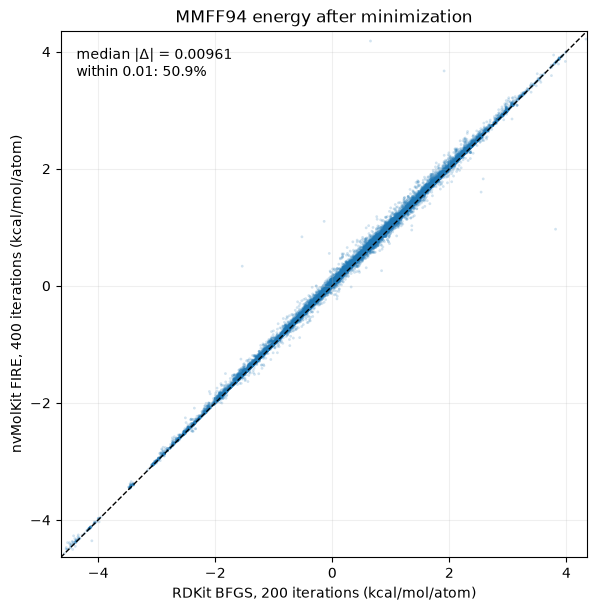

In [11]:
rdkit_final_energies = np.concatenate(mmff94_energies_per_atom(rdkit_ff_mols))
nvmolkit_fire_final_energies = np.concatenate(
    mmff94_energies_per_atom(nvmolkit_fire_mols)
)
energy_differences = nvmolkit_fire_final_energies - rdkit_final_energies

fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
identity_panel(
    ax,
    rdkit_final_energies,
    nvmolkit_fire_final_energies,
    "MMFF94 energy after minimization",
    f"median |Δ| = {np.median(np.abs(energy_differences)):.3g}\n"
    f"within 0.01: {np.mean(np.abs(energy_differences) <= 0.01):.1%}",
    s=4,
    alpha=0.2,
)
ax.set_xlabel(f"RDKit BFGS, {max_mmff_iters} iterations (kcal/mol/atom)")
ax.set_ylabel(f"nvMolKit FIRE, {fire_iters} iterations (kcal/mol/atom)")
plt.show()

## Step 3: 3D descriptors

3D descriptors are commonly used to characterize conformer shapes, for example as
features for a model. nvMolKit implements many of RDKit's 3D descriptors on the
GPU. We calculate two groups for every conformer:

* **The shape descriptors from RDKit's `Descriptors3D` module:** principal moments
  of inertia (PMI1-3), normalized PMI ratios (NPR1, NPR2), radius of gyration,
  inertial shape factor, eccentricity, asphericity, spherocity index, and plane of
  best fit (PBF). These are inexpensive and easy to interpret.
* **Four descriptor vectors:** WHIM (114 values), RDF (210), 3D-MoRSE (224), and
  GETAWAY (273). These are considerably more expensive to calculate and show the
  largest GPU speedups.

This gives 832 values per conformer. RDKit's 3D descriptor functions process one
conformer per call and have no thread-count option, so the CPU calculation is
distributed over a pool of 16 worker processes. On the GPU, a single
`Calc3DProperties` call computes every requested descriptor for every conformer in
the batch. Both start from the nvMolKit-minimized conformers from step 2.

Note that RDKit caches a molecule's principal axes, and `CalcPBF` reuses the cached
axes even when called for a different conformer. When calculating PBF for multiple
conformers of one molecule, clear the cache with `mol.ClearComputedProps()` before
each call, as `calc_pbf` does below.

In [12]:
scalar_descriptors = [
    "PMI1",
    "PMI2",
    "PMI3",
    "NPR1",
    "NPR2",
    "RadiusOfGyration",
    "InertialShapeFactor",
    "Eccentricity",
    "Asphericity",
    "SpherocityIndex",
    "PBF",
]
vector_descriptors = ["WHIM", "RDF", "MORSE", "GETAWAY"]
descriptor_names = scalar_descriptors + vector_descriptors


def calc_pbf(mol, confId):
    # CalcPBF reuses principal axes cached on the molecule by earlier calls,
    # even for a different conformer, so clear the cache first.
    mol.ClearComputedProps()
    return rdMolDescriptors.CalcPBF(mol, confId=confId)


rdkit_descriptor_functions = {
    "PMI1": rdMolDescriptors.CalcPMI1,
    "PMI2": rdMolDescriptors.CalcPMI2,
    "PMI3": rdMolDescriptors.CalcPMI3,
    "NPR1": rdMolDescriptors.CalcNPR1,
    "NPR2": rdMolDescriptors.CalcNPR2,
    "RadiusOfGyration": rdMolDescriptors.CalcRadiusOfGyration,
    "InertialShapeFactor": rdMolDescriptors.CalcInertialShapeFactor,
    "Eccentricity": rdMolDescriptors.CalcEccentricity,
    "Asphericity": rdMolDescriptors.CalcAsphericity,
    "SpherocityIndex": rdMolDescriptors.CalcSpherocityIndex,
    "PBF": calc_pbf,
    "WHIM": rdMolDescriptors.CalcWHIM,
    "RDF": rdMolDescriptors.CalcRDF,
    "MORSE": rdMolDescriptors.CalcMORSE,
    "GETAWAY": rdMolDescriptors.CalcGETAWAY,
}


def rdkit_descriptors_for_molecule(mol):
    # Returns {descriptor name: array with one row per conformer}
    results = {}
    conf_ids = [conf.GetId() for conf in mol.GetConformers()]
    for name in descriptor_names:
        func = rdkit_descriptor_functions[name]
        results[name] = np.asarray([func(mol, confId=conf_id) for conf_id in conf_ids])
    return results


descriptor_mols = [Chem.Mol(m) for m in nvmolkit_fire_mols]

# Start the worker processes before timing, just like the GPU warmup.
process_pool = ProcessPoolExecutor(
    n_cpu_threads, mp_context=multiprocessing.get_context("fork")
)
list(process_pool.map(rdkit_descriptors_for_molecule, descriptor_mols[:n_cpu_threads]))
Calc3DProperties(descriptor_mols[:4], descriptor_names)[descriptor_names[0]].numpy()
torch.cuda.synchronize()

In [13]:
t0 = perf_counter()
rdkit_per_molecule = list(
    process_pool.map(rdkit_descriptors_for_molecule, descriptor_mols, chunksize=8)
)
rdkit_descriptors = {
    name: np.concatenate([r[name] for r in rdkit_per_molecule]).reshape(-1, 1)
    if name in scalar_descriptors
    else np.concatenate([r[name] for r in rdkit_per_molecule])
    for name in descriptor_names
}
rdkit_descriptor_time = perf_counter() - t0
process_pool.shutdown()
print(f"RDKit 3D descriptors: {rdkit_descriptor_time:.2f} s")

RDKit 3D descriptors: 8.29 s


In [14]:
t0 = perf_counter()
nvmolkit_descriptor_results = Calc3DProperties(
    descriptor_mols, descriptor_names, hardwareOptions=hardware_options
)
nvmolkit_descriptors = {
    name: nvmolkit_descriptor_results[name].numpy().reshape(
        nvmolkit_descriptor_results.n_conformers, -1
    )
    for name in descriptor_names
}
nvmolkit_descriptor_time = perf_counter() - t0
print(f"nvMolKit 3D descriptors: {nvmolkit_descriptor_time:.3f} s")
print(
    f"{nvmolkit_descriptor_results.n_conformers:,} conformers x "
    f"{sum(v.shape[1] for v in nvmolkit_descriptors.values())} values"
)

nvMolKit 3D descriptors: 0.080 s
49,950 conformers x 832 values


`Calc3DProperties` computes in single precision by default, which is sufficient
for most descriptor applications, such as model features.
`precision=PrecisionMode.FULL` gives results that match RDKit to double-precision
rounding.

### Descriptor agreement

Both results list rows in the same order (molecule, then conformer), so they can be
compared value by value. The table below lists, for each descriptor, the fraction
of values within a relative tolerance of $10^{-3}$ of RDKit's (absolute tolerance
of $10^{-3}$ for values near zero), along with the largest absolute difference.

In [15]:
agreement = []
for name in descriptor_names:
    ref = rdkit_descriptors[name]
    gpu = nvmolkit_descriptors[name].astype(np.float64)
    finite = np.isfinite(ref) & np.isfinite(gpu)
    close = np.isclose(gpu[finite], ref[finite], rtol=1e-3, atol=1e-3)
    agreement.append(
        {
            "descriptor": name,
            "values per conformer": ref.shape[1],
            "within tolerance": close.mean(),
            "max |Δ|": np.abs(gpu[finite] - ref[finite]).max(),
        }
    )
agreement = pd.DataFrame(agreement).set_index("descriptor")
agreement.style.format({"within tolerance": "{:.3%}", "max |Δ|": "{:.2g}"})

,values per conformer,within tolerance,max |Δ|
descriptor,,,
PMI1,1,100.000%,0.0017
PMI2,1,100.000%,0.0032
PMI3,1,100.000%,0.0033
NPR1,1,100.000%,2e-07
NPR2,1,100.000%,3.5e-07
RadiusOfGyration,1,100.000%,9.2e-07
InertialShapeFactor,1,100.000%,2.8e-09
Eccentricity,1,100.000%,2e-07
Asphericity,1,100.000%,4.2e-07


The normalized PMI plot gives a more familiar view of the same data, placing each
conformer in a triangle whose corners correspond to rod-like, disc-like, and
sphere-like shapes. The two panels should be indistinguishable.

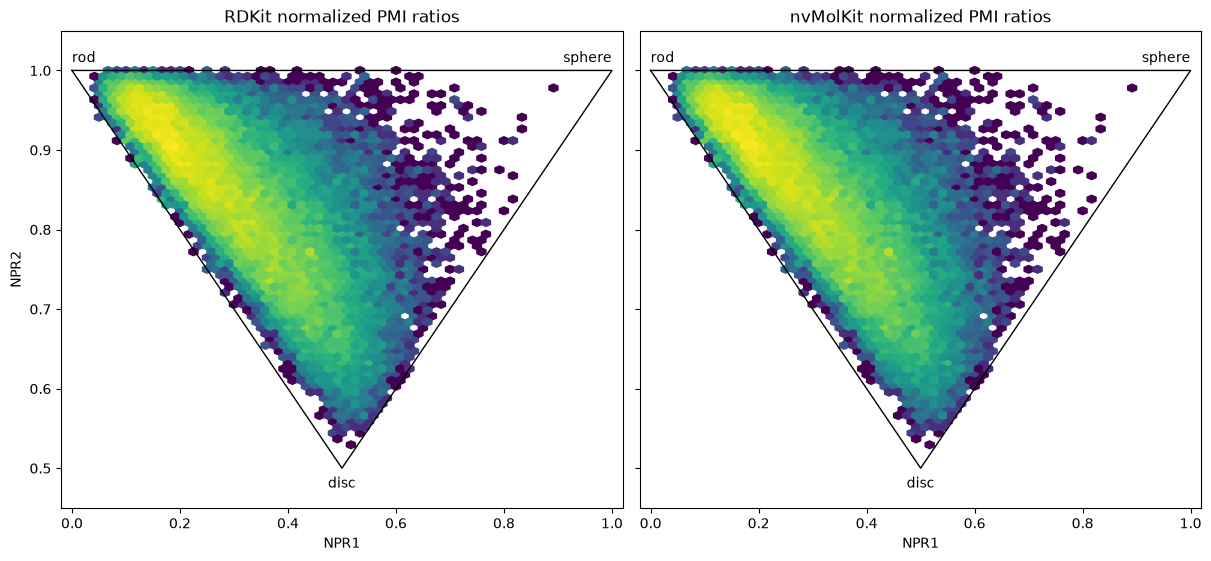

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True, constrained_layout=True)
for ax, label, values in zip(
    axes, ["RDKit", "nvMolKit"], [rdkit_descriptors, nvmolkit_descriptors]
):
    ax.hexbin(
        values["NPR1"].ravel(),
        values["NPR2"].ravel(),
        gridsize=60,
        bins="log",
        mincnt=1,
        cmap="viridis",
        extent=(0, 1, 0.5, 1),
    )
    ax.plot([0, 0.5, 1, 0], [1, 0.5, 1, 1], color="black", linewidth=1)
    for x, y, text, ha in [(0, 1, "rod", "left"), (0.5, 0.5, "disc", "center"), (1, 1, "sphere", "right")]:
        ax.annotate(text, (x, y), textcoords="offset points", xytext=(0, 6 if y == 1 else -14), ha=ha)
    ax.set(title=f"{label} normalized PMI ratios", xlabel="NPR1", xlim=(-0.02, 1.02), ylim=(0.45, 1.05))
axes[0].set_ylabel("NPR2")
plt.show()

## Step 4: TFD matrices and conformer pruning

A 50-conformer ensemble typically contains many near-duplicates. A common pruning
approach clusters each molecule's conformers by torsion fingerprint deviation
(TFD), which measures differences in rotatable-bond torsions and is independent of
conformer alignment.

Both implementations calculate the full TFD matrix for each molecule from the same
minimized conformers, with explicit hydrogens removed. Only the TFD calculation is
timed. Each implementation's matrices are then clustered with Butina at a 0.10
cutoff, keeping one representative conformer per cluster. The left panel below
compares the pairwise TFD distributions, and the right panel compares the number of
conformers retained per molecule.

RDKit TFD: 3.31 s
nvMolKit TFD: 0.013 s


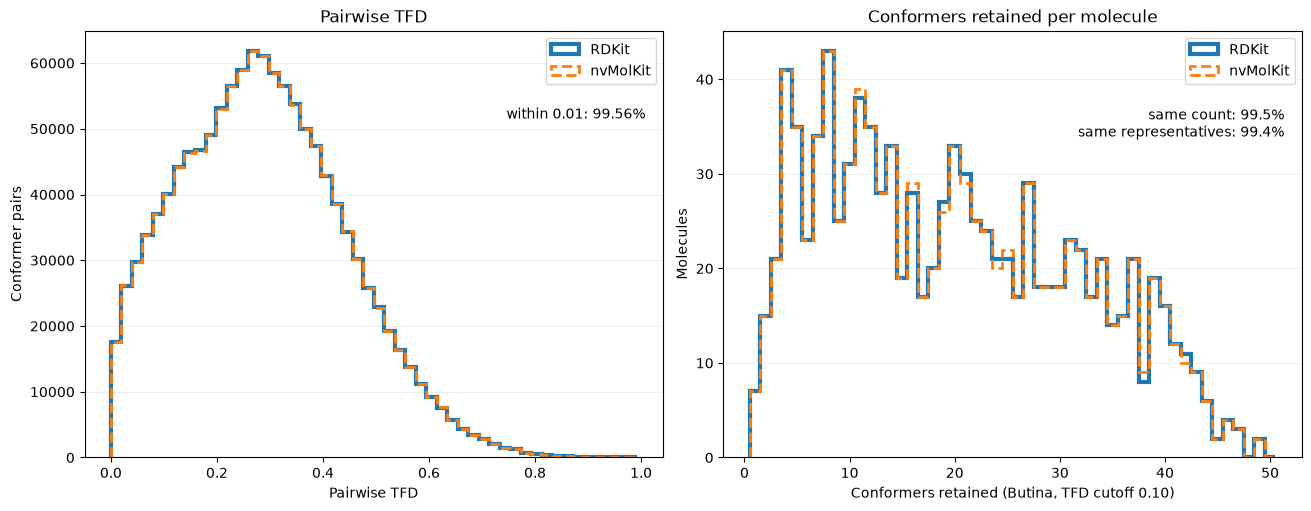

In [17]:
rdkit_tfd_mols = [Chem.RemoveHs(Chem.Mol(m)) for m in nvmolkit_fire_mols]
nvmolkit_tfd_mols = [Chem.Mol(m) for m in rdkit_tfd_mols]

t0 = perf_counter()
nvmolkit_tfd_results = GetTFDMatrices(nvmolkit_tfd_mols, return_type="numpy")
torch.cuda.synchronize()
nvmolkit_tfd_time = perf_counter() - t0

t0 = perf_counter()
rdkit_tfd_results = [
    TorsionFingerprints.GetTFDMatrix(mol, useWeights=True, maxDev="equal")
    for mol in rdkit_tfd_mols
]
rdkit_tfd_time = perf_counter() - t0
print(f"RDKit TFD: {rdkit_tfd_time:.2f} s")
print(f"nvMolKit TFD: {nvmolkit_tfd_time:.3f} s")

# Prune each ensemble with Butina clustering on each implementation's TFD matrix.
tfd_pruning_cutoff = 0.10
rdkit_tfd_values, nvmolkit_tfd_values = [], []
rdkit_retained, nvmolkit_retained, same_representatives = [], [], []
for mol, rdkit_distances, nvmolkit_distances in zip(
    rdkit_tfd_mols, rdkit_tfd_results, nvmolkit_tfd_results
):
    rdkit_distances = np.asarray(rdkit_distances)
    nvmolkit_distances = np.asarray(nvmolkit_distances)
    if not len(rdkit_distances):
        continue
    rdkit_tfd_values.append(rdkit_distances)
    nvmolkit_tfd_values.append(nvmolkit_distances)

    n = mol.GetNumConformers()
    rdkit_clusters = Butina.ClusterData(rdkit_distances, n, tfd_pruning_cutoff, isDistData=True)
    nvmolkit_clusters = Butina.ClusterData(nvmolkit_distances, n, tfd_pruning_cutoff, isDistData=True)
    rdkit_retained.append(len(rdkit_clusters))
    nvmolkit_retained.append(len(nvmolkit_clusters))
    same_representatives.append(
        {c[0] for c in rdkit_clusters} == {c[0] for c in nvmolkit_clusters}
    )

rdkit_tfd_values = np.concatenate(rdkit_tfd_values)
nvmolkit_tfd_values = np.concatenate(nvmolkit_tfd_values)
rdkit_retained = np.asarray(rdkit_retained)
nvmolkit_retained = np.asarray(nvmolkit_retained)
same_representatives = np.asarray(same_representatives)
tfd_abs_differences = np.abs(rdkit_tfd_values - nvmolkit_tfd_values)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
tfd_bins = np.linspace(0, max(rdkit_tfd_values.max(), nvmolkit_tfd_values.max()), 51)
retained_bins = np.arange(0.5, n_confs + 1.5, 1)
for ax, (rd, nv, bins) in zip(
    axes,
    [
        (rdkit_tfd_values, nvmolkit_tfd_values, tfd_bins),
        (rdkit_retained, nvmolkit_retained, retained_bins),
    ],
):
    ax.hist(rd, bins=bins, histtype="step", linewidth=3, label="RDKit")
    ax.hist(nv, bins=bins, histtype="step", linewidth=2, linestyle="--", label="nvMolKit")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right")
axes[0].set(xlabel="Pairwise TFD", ylabel="Conformer pairs", title="Pairwise TFD")
axes[0].text(
    0.97, 0.82,
    f"within 0.01: {np.mean(tfd_abs_differences <= 0.01):.2%}",
    transform=axes[0].transAxes, ha="right", va="top",
)
axes[1].set(
    xlabel=f"Conformers retained (Butina, TFD cutoff {tfd_pruning_cutoff:.2f})",
    ylabel="Molecules",
    title="Conformers retained per molecule",
)
axes[1].text(
    0.97, 0.82,
    f"same count: {np.mean(rdkit_retained == nvmolkit_retained):.1%}\n"
    f"same representatives: {same_representatives.mean():.1%}",
    transform=axes[1].transAxes, ha="right", va="top",
)
plt.show()

## Performance comparison

The workflow total is the sum of the four timed steps. Molecule loading, copies,
warmup, validation re-scoring, and plotting are excluded.

In [18]:
timings = pd.DataFrame(
    {
        "RDKit (s)": [rdkit_embed_time, rdkit_mmff_time, rdkit_descriptor_time, rdkit_tfd_time],
        "nvMolKit (s)": [nvmolkit_embed_time, nvmolkit_fire_time, nvmolkit_descriptor_time, nvmolkit_tfd_time],
    },
    index=["ETKDG", "MMFF94", "3D descriptors", "TFD"],
)
timings.loc["Total"] = timings.sum()
timings["Speedup"] = timings["RDKit (s)"] / timings["nvMolKit (s)"]
timings.style.format({"RDKit (s)": "{:.2f}", "nvMolKit (s)": "{:.3f}", "Speedup": "{:.1f}x"})

,RDKit (s),nvMolKit (s),Speedup
ETKDG,113.43,19.819,5.7x
MMFF94,68.62,3.759,18.3x
3D descriptors,8.29,0.080,103.6x
TFD,3.31,0.013,254.9x
Total,193.65,23.671,8.2x


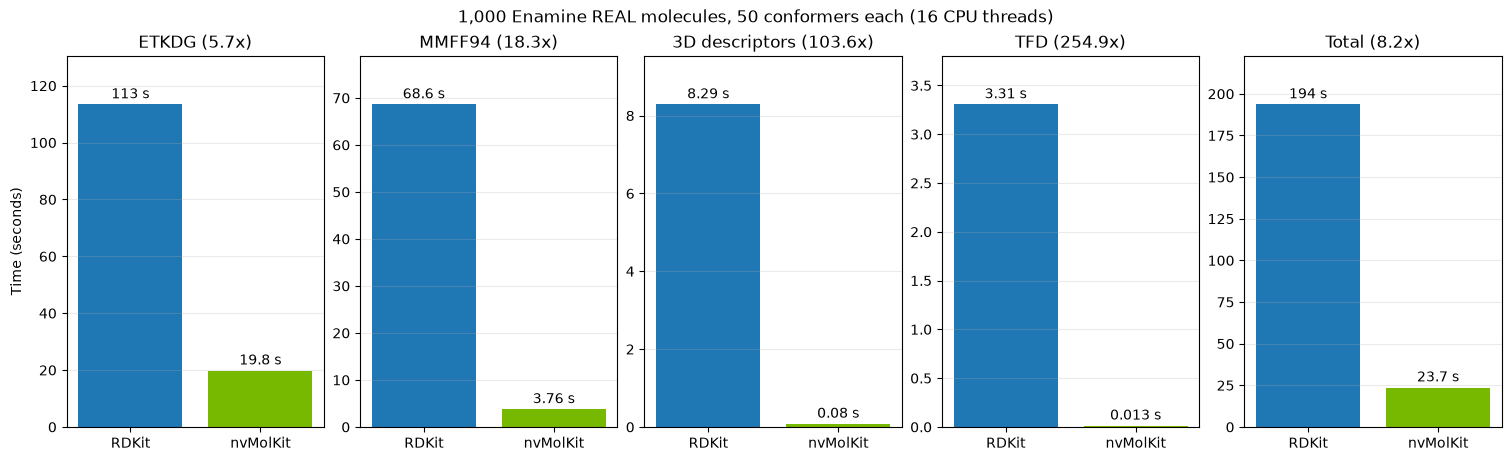

In [19]:
fig, axes = plt.subplots(1, len(timings), figsize=(15, 4.5), constrained_layout=True)
for ax, (step, row) in zip(axes, timings.iterrows()):
    values = [row["RDKit (s)"], row["nvMolKit (s)"]]
    bars = ax.bar(["RDKit", "nvMolKit"], values, color=["#1f77b4", "#76b900"])
    ax.bar_label(bars, labels=[f"{v:.3g} s" for v in values], padding=2)
    ax.set_ylim(0, max(values) * 1.15)
    ax.set_title(f"{step} ({row['Speedup']:.1f}x)")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Time (seconds)")
fig.suptitle(
    f"{n_mols:,} Enamine REAL molecules, {n_confs} conformers each "
    f"({n_cpu_threads} CPU threads)"
)
plt.show()

On this hardware, the GPU workflow is about 8x faster than RDKit end to end. ETKDG
accounts for most of the GPU runtime and largely determines the overall speedup.
The descriptor and TFD steps drop from seconds to tens of milliseconds, making it
inexpensive to calculate many more descriptors, or descriptors for many more
conformers.

Single precision contributes substantially. With `PrecisionMode.FULL`, the GPU
stages took 45 s for ETKDG (vs. 19 s) and 18 s for FIRE (vs. 4 s), which is still
roughly 3x faster than RDKit end to end. The gap between precisions is largest on
consumer GPUs such as the RTX 5080, which have limited double-precision throughput,
and is considerably smaller on datacenter GPUs.

## Appendix: choosing the FIRE iteration budget

FIRE does less work per step than BFGS but typically needs more steps on drug-like
molecules, so its iteration limit trades speed for fidelity. The appropriate value
is application-specific and worth measuring on your own data.

To choose a value for this post, we ran FIRE with 200, 400, and 600 iterations on a
separate set of 500 Enamine REAL molecules with 50 conformers each. All runs
started from the same nvMolKit ETKDG coordinates and used single precision, and all
final geometries were re-scored with RDKit MMFF94. The reference is nvMolKit BFGS
with 200 iterations.

| FIRE iterations | FIRE time | FIRE lower | median $\Delta E$ | median $|\Delta E|$ | $|\Delta E| \le 10^{-4}$ | $|\Delta E| \le 10^{-3}$ |
|---:|---:|---:|---:|---:|---:|---:|
| 200 | 0.26 s | 1.7% | 7.1e-3 | 7.5e-3 | 8.6% | 24.4% |
| 400 | 0.45 s | 15.3% | 5.7e-5 | 9.2e-5 | 50.6% | 66.9% |
| 600 | 0.63 s | 43.3% | 1.3e-7 | 1.1e-6 | 75.1% | 82.5% |

BFGS took 1.29 s on the same 25,000 conformers.

$\Delta E$ is `(FIRE - BFGS) / atom` in kcal/mol; negative values indicate that
FIRE found the lower energy. "FIRE lower" is the fraction of conformers where this
occurred.

At 200 iterations, most conformers remain noticeably above the BFGS energy. At 400
iterations, the median difference is below $10^{-4}$ kcal/mol/atom, and at 600 the
two minimizers are essentially equivalent, with FIRE finding the lower energy for
almost half of the conformers. We chose 400 iterations as a balance between speed
and fidelity; it is about 3x faster than BFGS. For applications that need tighter
minimization, 600 iterations is still about twice as fast as BFGS.

![FIRE versus BFGS final energies](images/nvmolkit_fire_energy_vs_energy.png)

![FIRE minus BFGS energy distributions](images/nvmolkit_fire_energy_difference_histograms.png)

The histograms show the central 99% of each distribution. Outliers are excluded
from the plotted range only and are included in the table.